In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (6,3)

In [7]:
def plot_data(df, x, y, title, x_label, y_label):
    fig, ax = plt.subplots()
    for key, grp in df.groupby(['optimizer']):
        ax = grp.plot(ax=ax, kind='line', x=x, y=y, label=key[0])
    ax.set_title(title, fontdict={'fontweight':'bold'})
    ax.set_xlabel(xlabel=x_label)
    ax.xaxis.get_label().set_fontstyle('italic')
    ax.yaxis.get_label().set_fontstyle('italic')
    ax.set_ylabel(ylabel=y_label)
    ax.grid(visible=True)
    plt.legend(loc='best')    
    plt.show()


In [8]:
df = pd.read_csv('classical_results.csv')
df

,n_features,n_targets,n_samples,test_size,optimizer,iterations,training_time,prediction_time,r2,mae,mse,rmse
0,3,2,100,20,lbfgs,100000,0.012001,0.000,0.837646,0.086021,0.010123,0.096702
1,3,2,100,20,adam,100,0.014000,0.000,-0.001352,0.216655,0.063625,0.249157
2,3,2,100,30,adam,10000,0.020002,0.000,0.650052,0.088961,0.014436,0.120056
3,3,2,100,30,sgd,1000,0.019002,0.000,0.156106,0.139772,0.035301,0.187776
4,3,2,100,30,sgd,10000,0.018001,0.000,0.238819,0.134889,0.032170,0.178659
...,...,...,...,...,...,...,...,...,...,...,...,...
103,3,2,1000,40,lbfgs,1000,0.070998,0.000,0.945077,0.049054,0.003478,0.058732
104,3,2,1000,40,sgd,100000,0.047000,0.001,0.053940,0.198715,0.059749,0.243298
105,3,2,1000,40,lbfgs,10000,0.036999,0.000,0.946512,0.048410,0.003386,0.058000
106,3,2,1000,40,lbfgs,100000,0.057000,0.000,0.943849,0.049931,0.003555,0.059445


In [9]:
df['training_time'] = df['training_time'].divide(3600)
df.sort_values(['r2'], ascending=False)

,n_features,n_targets,n_samples,test_size,optimizer,iterations,training_time,prediction_time,r2,mae,mse,rmse
55,3,2,500,30,lbfgs,10000,0.000007,0.000999,0.982473,0.024993,0.001031,0.031258
53,3,2,500,30,lbfgs,1000,0.000005,0.000000,0.979525,0.027335,0.001208,0.034057
52,3,2,500,30,lbfgs,100,0.000010,0.000000,0.978842,0.027766,0.001264,0.035374
58,3,2,500,30,lbfgs,100000,0.000006,0.000000,0.977937,0.027770,0.001301,0.035277
102,3,2,1000,30,lbfgs,10000,0.000012,0.000000,0.962540,0.039836,0.002453,0.048921
...,...,...,...,...,...,...,...,...,...,...,...,...
104,3,2,1000,40,sgd,100000,0.000013,0.001000,0.053940,0.198715,0.059749,0.243298
13,3,2,100,20,sgd,10000,0.000007,0.000000,0.008822,0.207819,0.065331,0.255187
1,3,2,100,20,adam,100,0.000004,0.000000,-0.001352,0.216655,0.063625,0.249157
5,3,2,100,20,sgd,100,0.000004,0.000000,-0.069252,0.206950,0.069758,0.264118


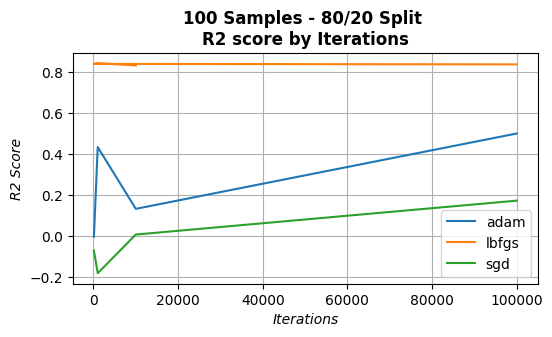

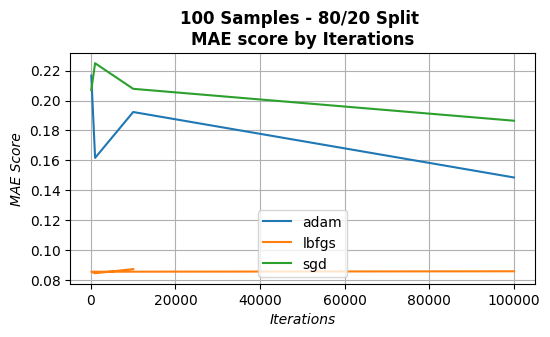

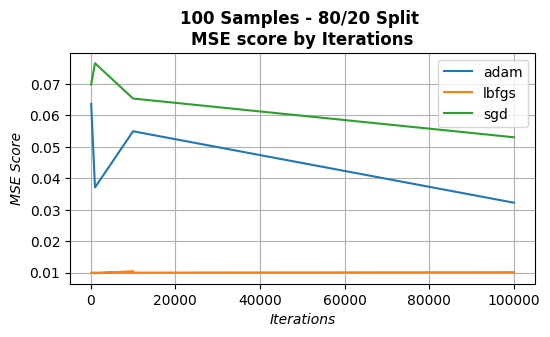

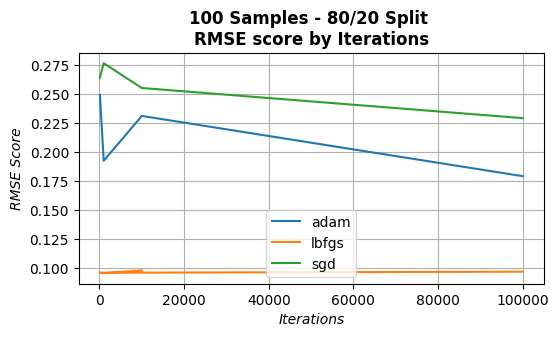

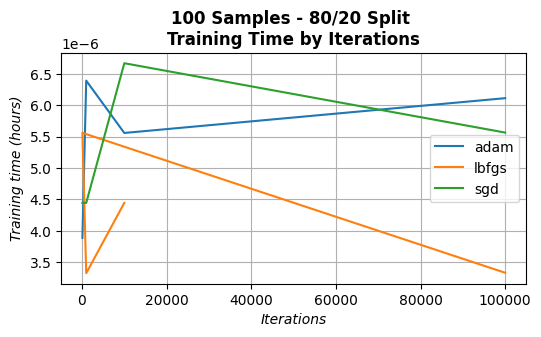

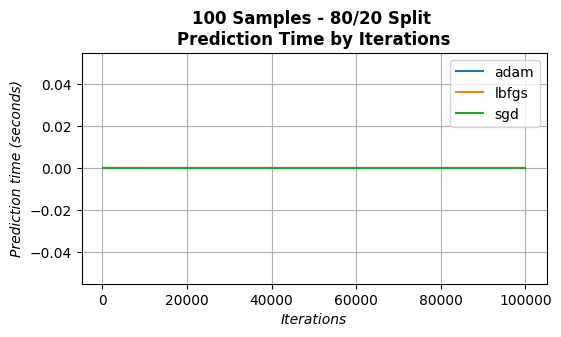

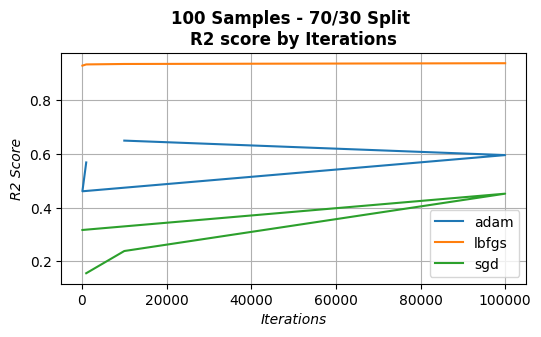

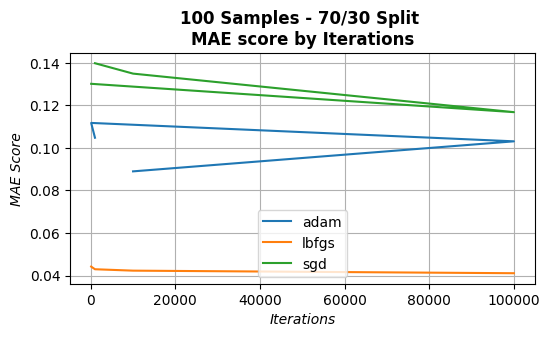

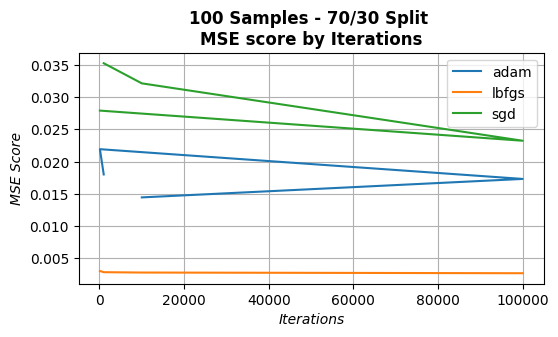

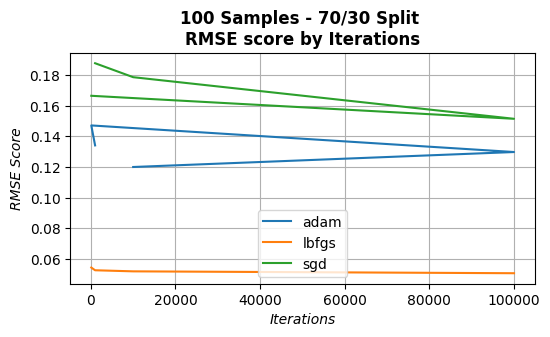

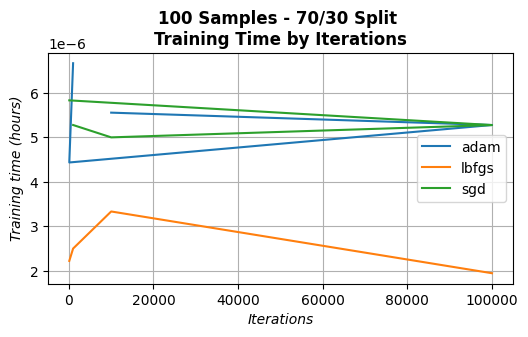

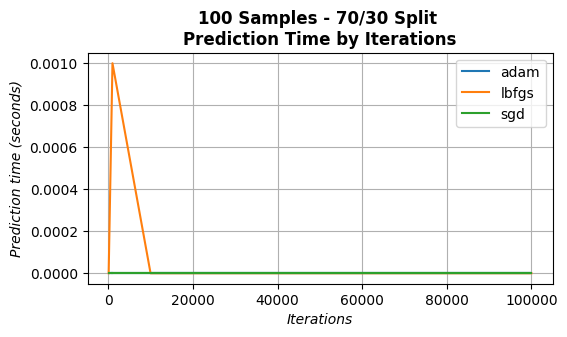

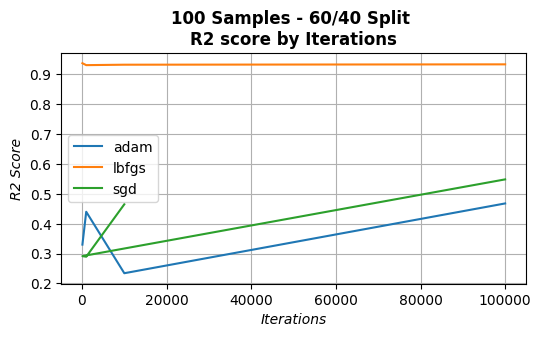

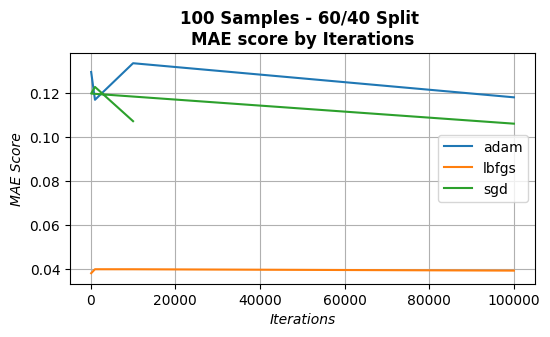

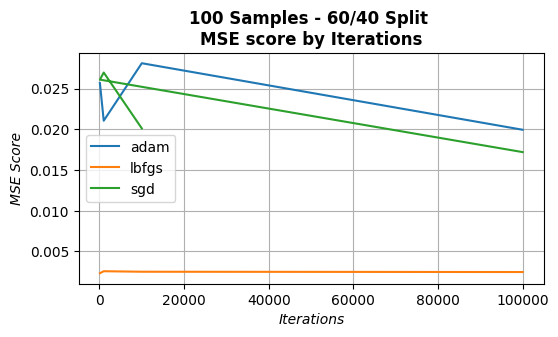

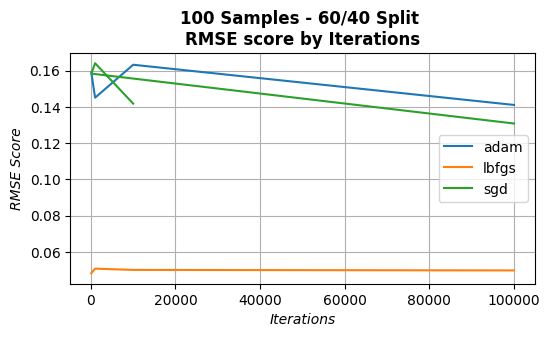

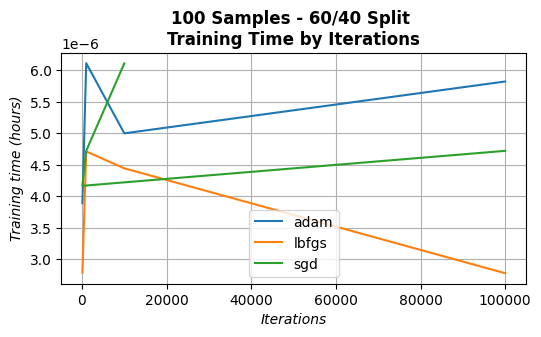

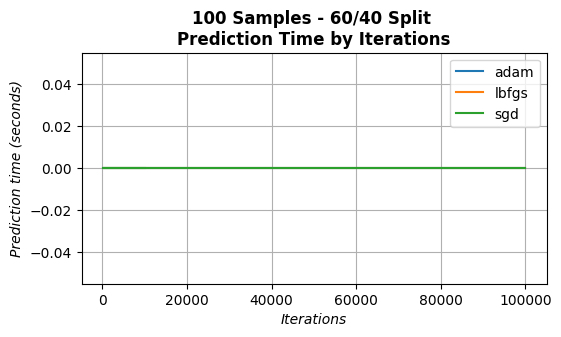

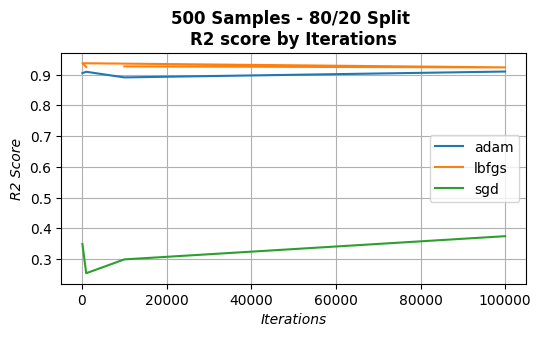

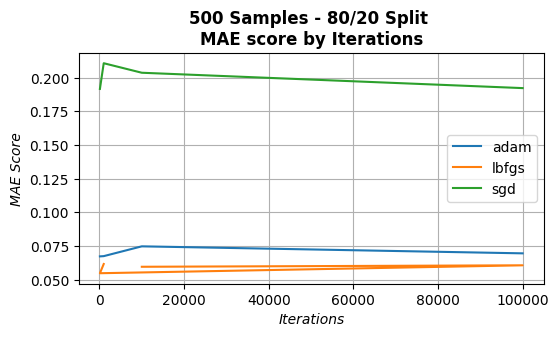

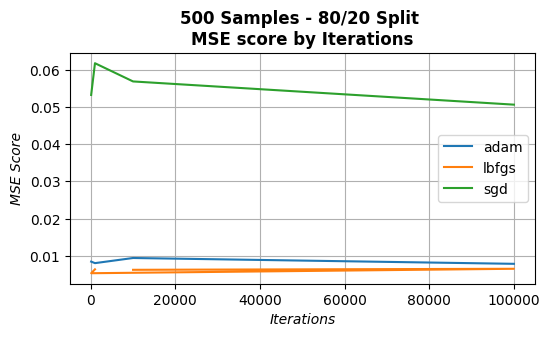

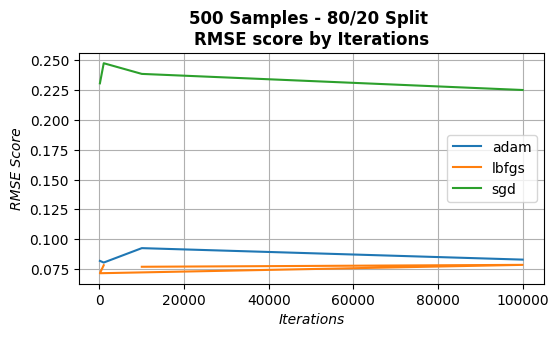

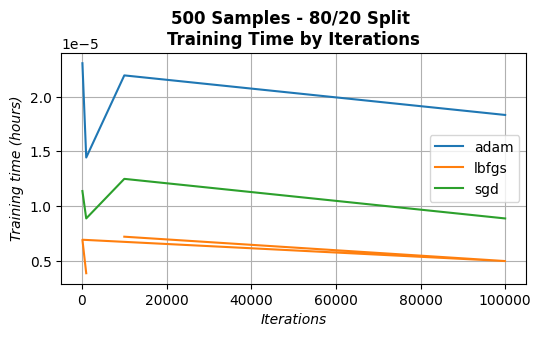

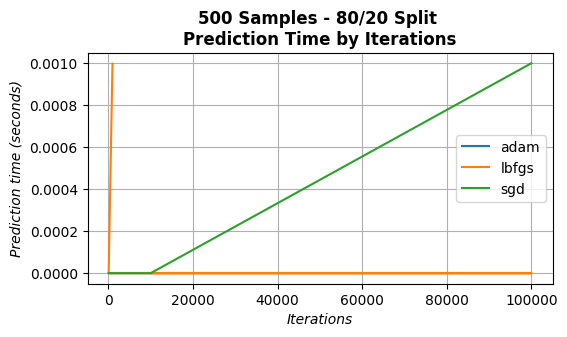

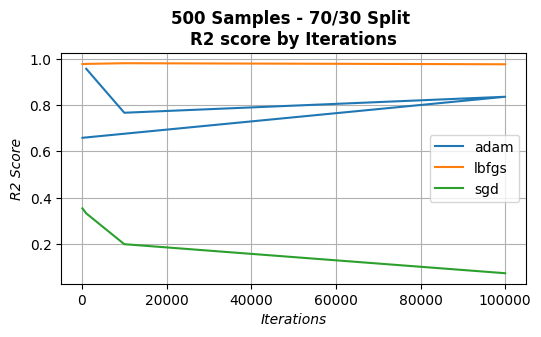

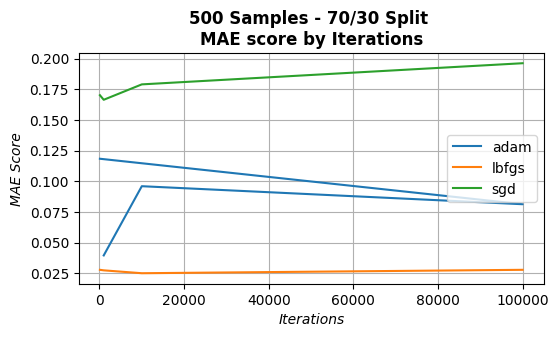

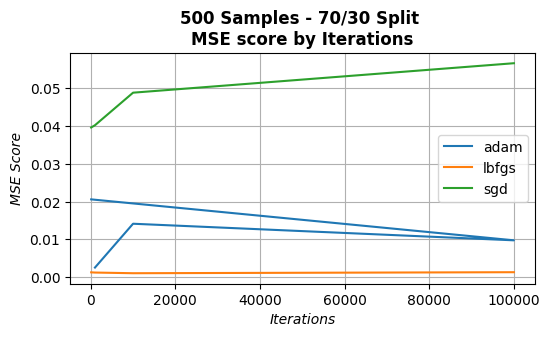

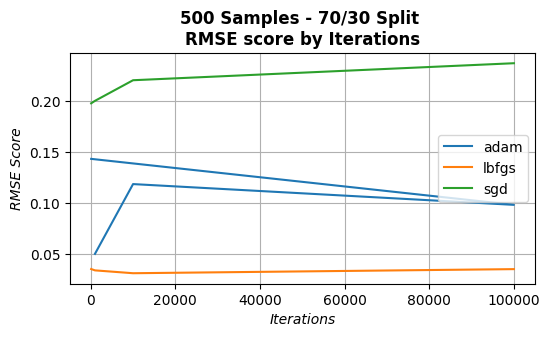

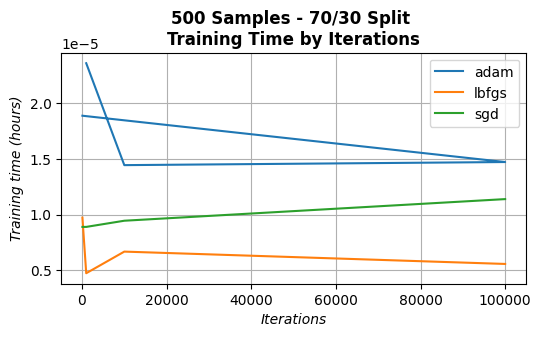

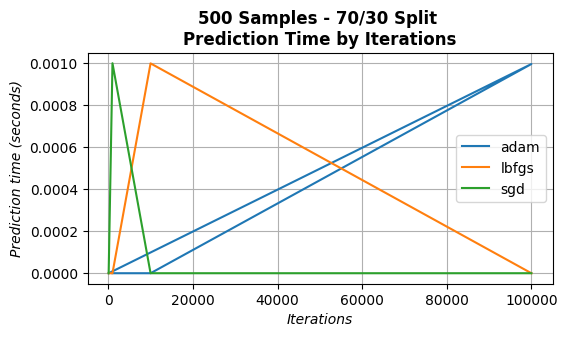

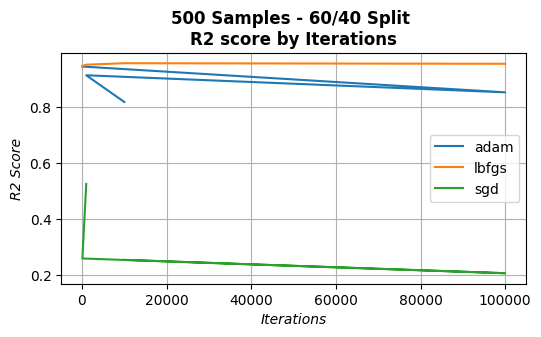

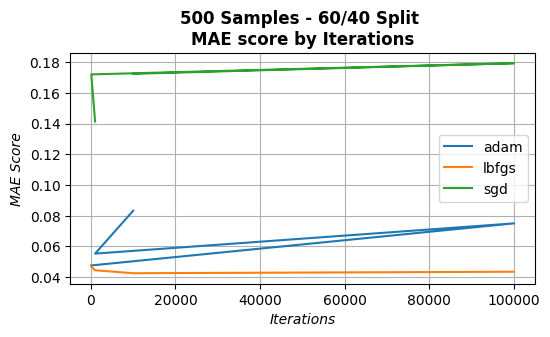

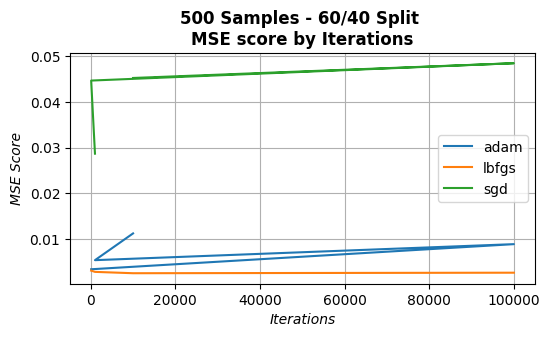

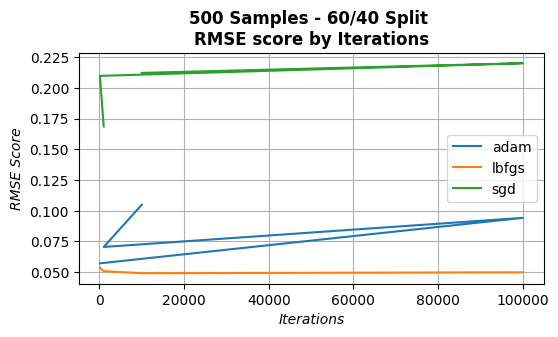

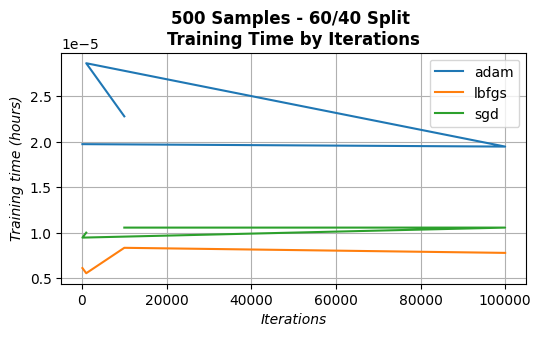

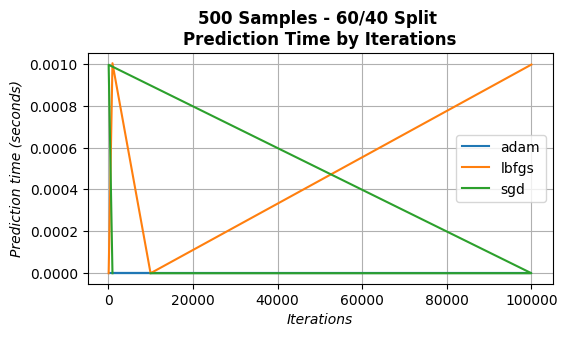

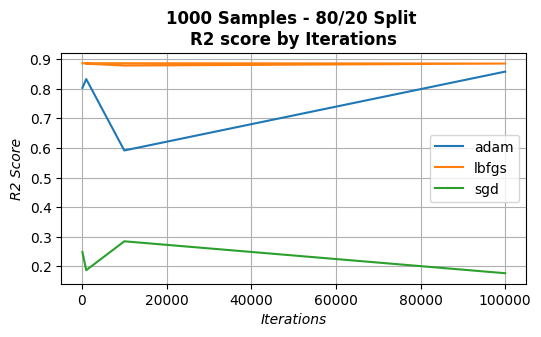

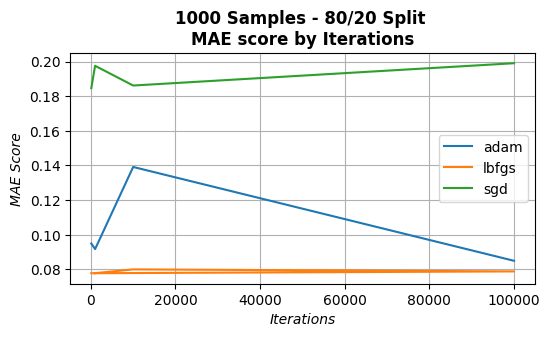

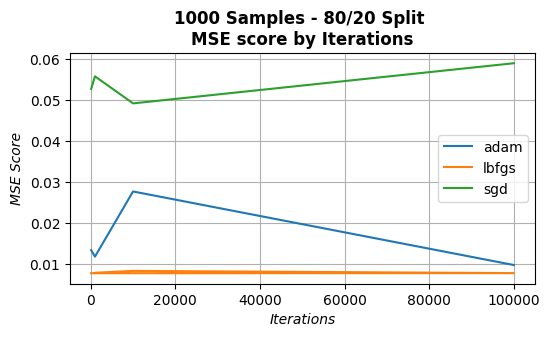

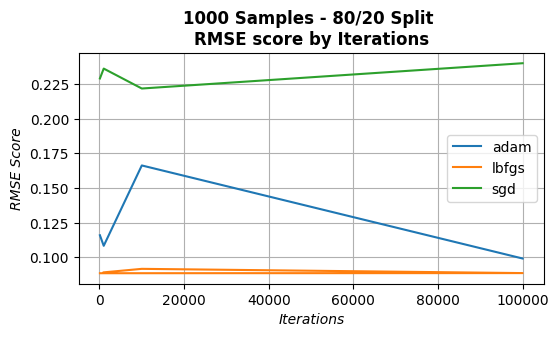

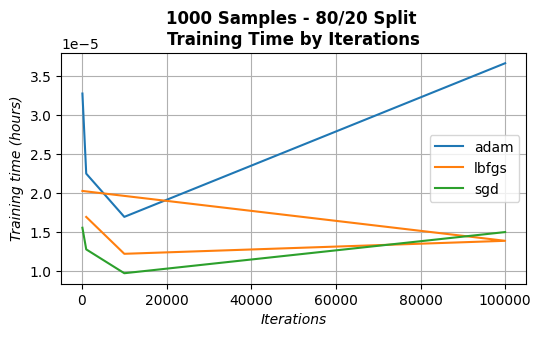

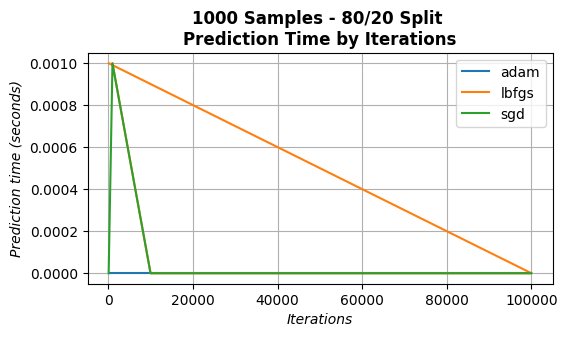

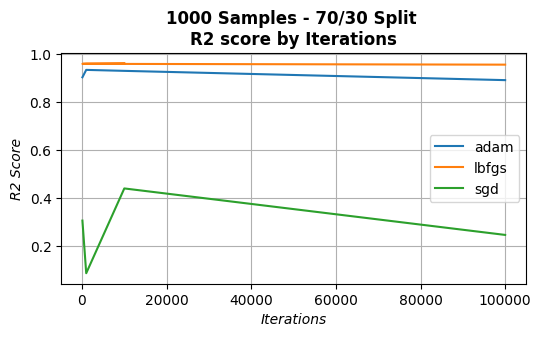

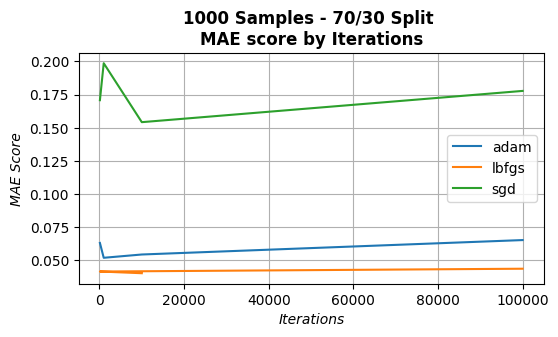

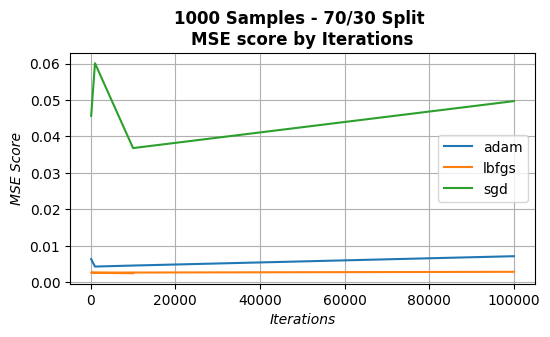

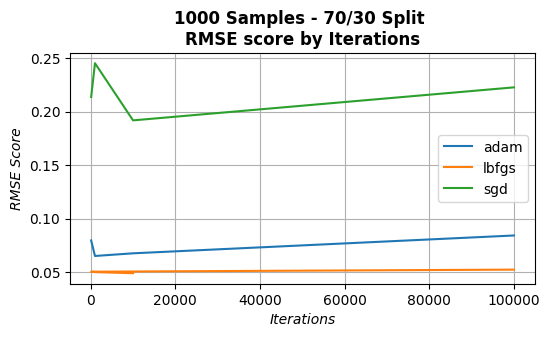

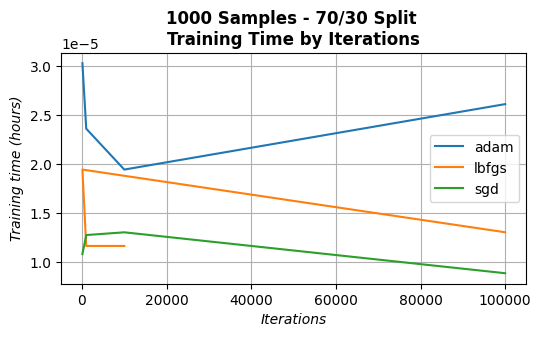

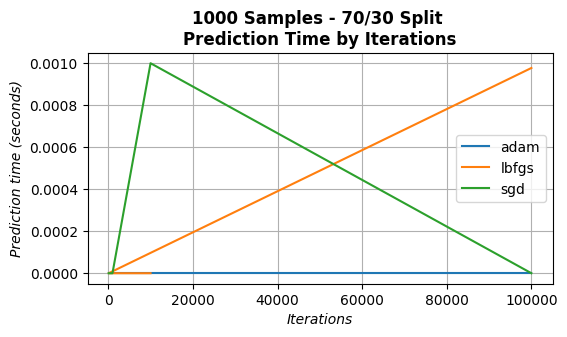

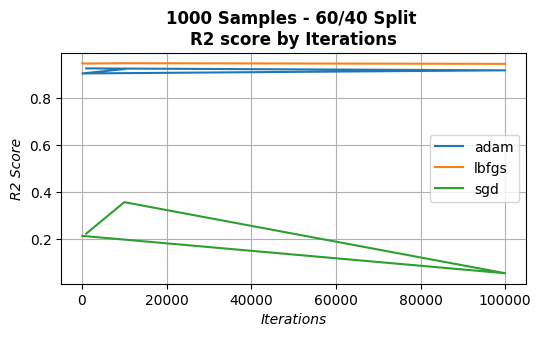

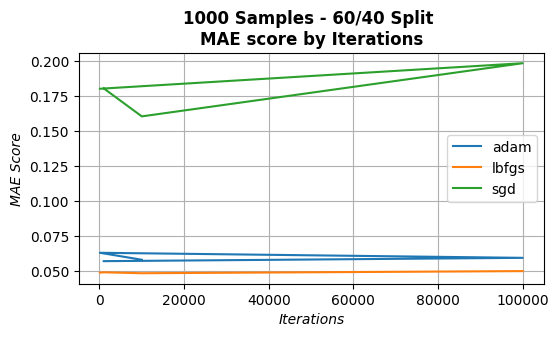

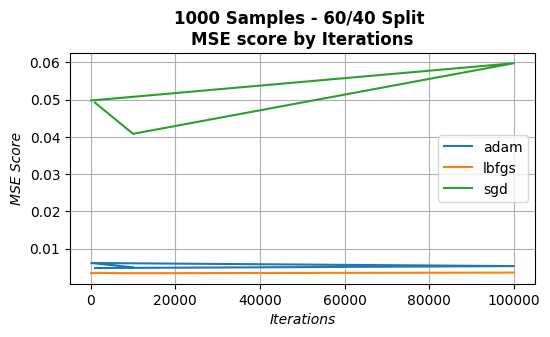

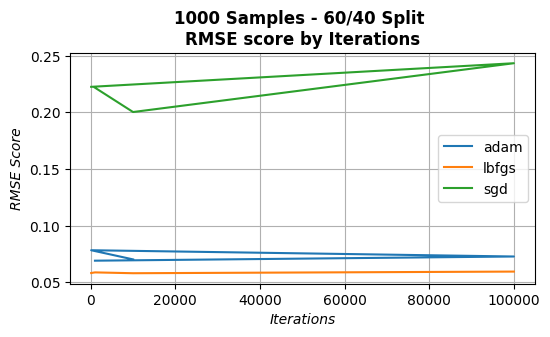

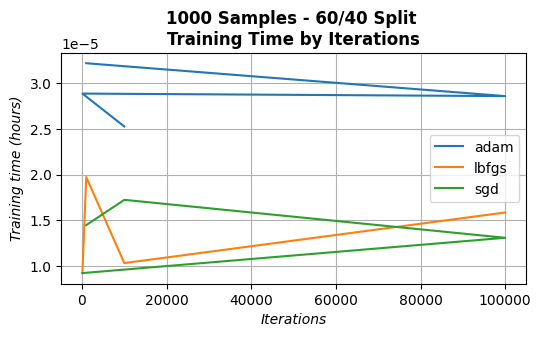

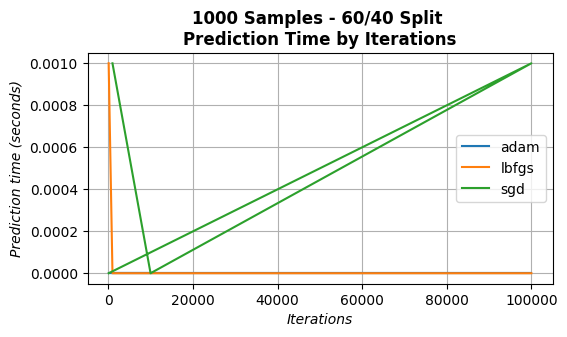

In [10]:
sample_sizes = [100, 500, 1000]
test_sizes = [20, 30, 40]
performance_metrics = ['r2', 'mae', 'mse', 'rmse']
for sample_size in sample_sizes:
    for test_size in test_sizes:
        df_nsamples_by_split = df[(df['n_samples']==sample_size) & (df['test_size'] == test_size)]
        for performance_metric in performance_metrics:
            plot_data(df_nsamples_by_split, 'iterations', performance_metric, f'{sample_size} Samples - {100-test_size}/{test_size} Split \n{performance_metric.upper()} score by Iterations', 'Iterations', f'{performance_metric.upper()} Score')
        plot_data(df_nsamples_by_split, 'iterations', 'training_time', f"{sample_size} Samples - {100-test_size}/{test_size} Split \nTraining Time by Iterations", "Iterations", "Training time (hours)")
        plot_data(df_nsamples_by_split, 'iterations', 'prediction_time', f"{sample_size} Samples - {100-test_size}/{test_size} Split \nPrediction Time by Iterations", "Iterations", "Prediction time (seconds)")

#df_100_samples_by_80_20_split = df[(df['n_samples']==100) & (df['test_size'] == 20)]
#plot_data(df_100_samples_by_80_20_split, 'iterations', 'r2', '100 Samples - 80/20 Split - R2 score by Iterations', 'Iterations', 'R2 Score')